## Task 1: Load and inspect the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())
df.head()

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


The dataset has 240 rows and 6 columns, with no missing values. `ticket_id` is a text identifier, the other columns are numeric.

## Task 2: Define X and y, and justify feature selection

I'm treating this as predicting resolution time at the moment a ticket comes in, so I can only use things we'd actually know by then.

Features I'm using:
- `complexity_score`: this is estimated when the ticket is triaged, so it's available upfront.
- `team_experience_years`: we know which team is assigned before work starts.

Columns I'm leaving out:
- `ticket_id`: it's just a label for each row and says nothing about how long a fix takes.
- `lines_changed`: we only know how many lines were changed after the fix is done, so using it would be cheating. It is also highly correlated with the target (about 0.85), which would make the model look better than it really is.
- `reopened`: a ticket can only be reopened after it has been resolved, so this isn't known at prediction time either.

The target (y) is `resolution_hours`.

In [2]:
target = "resolution_hours"
features = ["complexity_score", "team_experience_years"]

y = df[target]
X = df[features]

# Correlations support the leakage concern: lines_changed is very strongly
# related to both complexity and the target, but is not known in advance.
print(df.drop(columns="ticket_id").corr().round(3))

                       complexity_score  lines_changed  team_experience_years  \
complexity_score                  1.000          0.913                 -0.069   
lines_changed                     0.913          1.000                 -0.043   
team_experience_years            -0.069         -0.043                  1.000   
reopened                          0.151          0.103                  0.028   
resolution_hours                  0.918          0.847                 -0.175   

                       reopened  resolution_hours  
complexity_score          0.151             0.918  
lines_changed             0.103             0.847  
team_experience_years     0.028            -0.175  
reopened                  1.000             0.301  
resolution_hours          0.301             1.000  


## Task 3: Train/test split

80/20 split with `random_state=42`. The test set is used only for final reporting. All model selection (polynomial degree, alpha) uses 5-fold cross-validation on the training set.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

# One CV splitter reused for every model so comparisons are fair
cv = KFold(n_splits=5, shuffle=True, random_state=42)

(192, 2) (48, 2)


## Task 4: Baseline (DummyRegressor, mean)

In [4]:
results = {}   # model name -> (MAE, RMSE, R2) on the test set
models = {}    # model name -> fitted model

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    results[name] = (mae, rmse, r2)
    models[name] = model
    print(f"{name:12s} MAE={mae:.3f}  RMSE={rmse:.3f}  R2={r2:.3f}")

evaluate("Dummy(mean)", DummyRegressor(strategy="mean"))

Dummy(mean)  MAE=9.114  RMSE=10.598  R2=-0.021


## Task 5: Linear regression

In [5]:
evaluate("Linear", LinearRegression())
print("Coefficients:", dict(zip(features, models["Linear"].coef_.round(3))))
print("Intercept:", round(models["Linear"].intercept_, 3))

Linear       MAE=2.906  RMSE=3.572  R2=0.884
Coefficients: {'complexity_score': np.float64(3.08), 'team_experience_years': np.float64(-0.318)}
Intercept: 4.249


## Task 6: Polynomial regression (degree 2 vs 3), compared with cross-validation on the training set

In [6]:
def cv_rmse(model):
    return -cross_val_score(model, X_train, y_train, cv=cv,
                            scoring="neg_root_mean_squared_error").mean()

poly_models = {
    d: make_pipeline(PolynomialFeatures(degree=d, include_bias=False),
                     StandardScaler(),
                     LinearRegression())
    for d in (2, 3)
}

print(f"Linear     CV RMSE: {cv_rmse(LinearRegression()):.3f}")
for d, m in poly_models.items():
    print(f"Poly deg {d} CV RMSE: {cv_rmse(m):.3f}")

Linear     CV RMSE: 3.909
Poly deg 2 CV RMSE: 3.832
Poly deg 3 CV RMSE: 3.877


In [7]:
# Test metrics for the table (not used to choose the degree)
for d, m in poly_models.items():
    evaluate(f"Poly{d}", m)

Poly2        MAE=3.020  RMSE=3.741  R2=0.873
Poly3        MAE=3.140  RMSE=3.949  R2=0.858


## Task 7: Ridge and Lasso (scaled pipeline, alpha chosen by cross-validation)

In [8]:
ridge_gs = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": np.logspace(-3, 3, 13)},
    cv=cv, scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)

lasso_gs = GridSearchCV(
    make_pipeline(StandardScaler(), Lasso(max_iter=10000)),
    {"lasso__alpha": np.logspace(-3, 1, 13)},
    cv=cv, scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)

print("Selected Ridge alpha:", ridge_gs.best_params_["ridge__alpha"])
print("Selected Lasso alpha:", lasso_gs.best_params_["lasso__alpha"])

evaluate("Ridge", ridge_gs.best_estimator_)
evaluate("Lasso", lasso_gs.best_estimator_)

Selected Ridge alpha: 0.31622776601683794
Selected Lasso alpha: 0.001
Ridge        MAE=2.906  RMSE=3.572  R2=0.884
Lasso        MAE=2.906  RMSE=3.572  R2=0.884


### Results summary and coefficient comparison

In [9]:
summary = pd.DataFrame(results, index=["MAE", "RMSE", "R2"]).T.round(3)
display(summary)

# Coefficients on the same standardized scale so they are comparable
ols_scaled = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
coef_table = pd.DataFrame({
    "OLS (scaled)": ols_scaled[-1].coef_,
    "Ridge": models["Ridge"][-1].coef_,
    "Lasso": models["Lasso"][-1].coef_,
}, index=features).round(3)
display(coef_table)

,MAE,RMSE,R2
Dummy(mean),9.114,10.598,-0.021
Linear,2.906,3.572,0.884
Poly2,3.020,3.741,0.873
Poly3,3.140,3.949,0.858
Ridge,2.906,3.572,0.884
Lasso,2.906,3.572,0.884


,OLS (scaled),Ridge,Lasso
complexity_score,8.995,8.980,8.994
team_experience_years,-1.078,-1.076,-1.077


## Task 8: Observed vs predicted and residual plots (Linear and Polynomial degree 2)

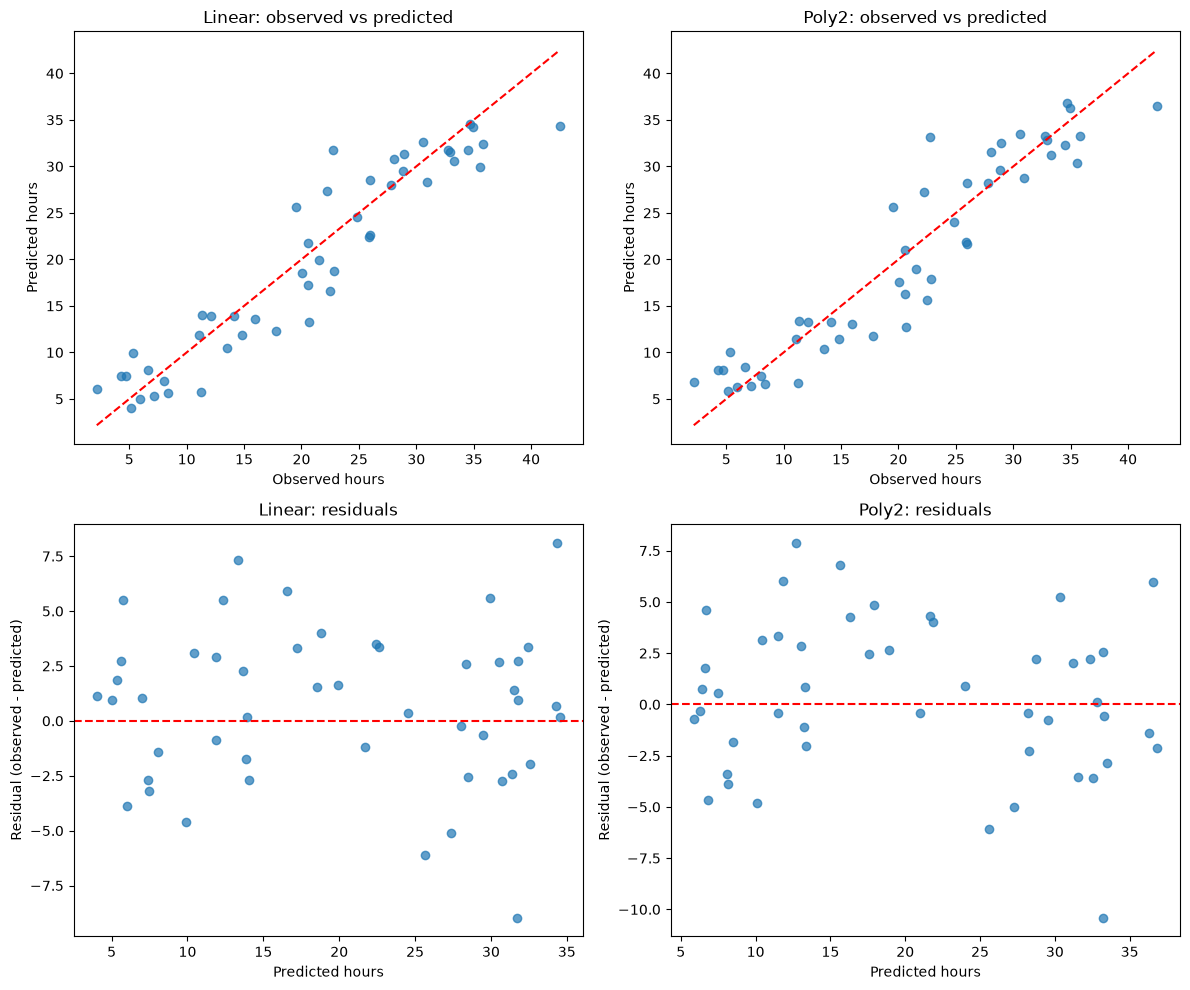

In [10]:
plot_models = ["Linear", "Poly2"]

fig, axes = plt.subplots(2, len(plot_models), figsize=(6 * len(plot_models), 10))

for j, name in enumerate(plot_models):
    pred = models[name].predict(X_test)
    resid = y_test - pred

    # Observed vs predicted
    ax = axes[0, j]
    ax.scatter(y_test, pred, alpha=0.7)
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(lims, lims, "r--")
    ax.set_xlabel("Observed hours")
    ax.set_ylabel("Predicted hours")
    ax.set_title(f"{name}: observed vs predicted")

    # Residuals vs predicted
    ax = axes[1, j]
    ax.scatter(pred, resid, alpha=0.7)
    ax.axhline(0, color="r", linestyle="--")
    ax.set_xlabel("Predicted hours")
    ax.set_ylabel("Residual (observed - predicted)")
    ax.set_title(f"{name}: residuals")

plt.tight_layout()
plt.show()

### Plot inspection
- Curvature: The linear model's residuals scatter around zero with no clear U-shape or curve, so a straight line captures the main relationship. The degree-2 model does not remove any visible pattern, which matches its lack of improvement in the metrics.
- Changing spread: The spread of residuals is roughly constant. It may be slightly larger at the highest predicted values, but there is no strong funnel shape.
- Influential outliers: A few tickets have residuals of about 7-10 hours (the largest is roughly 9 h for the linear model and 10 h for the polynomial model). They are isolated rather than a systematic cluster, but they would be worth examining individually.
- Bias: Residuals have a small positive average (about +0.7 h for the linear model), so on this test set the model slightly under-predicts on average.

## Task 9: Recommendation

I would choose linear regression (Ridge performs identically) using `complexity_score` and `team_experience_years`.

Evidence:
- It reaches a test R² of about 0.88, MAE of about 2.9 hours and RMSE of about 3.6 hours, compared with the mean baseline's R² of about 0 and RMSE of about 10.6 hours.
- Polynomial features gave only a tiny improvement in cross-validation at degree 2 (RMSE 3.83 vs 3.91), degree 3 was worse than degree 2, and both polynomial models scored worse than linear on the test set. The extra complexity is not justified.
- Ridge and Lasso selected very small alphas, so regularization gave essentially the same results as plain linear regression. With only two features and 192 training rows, there is little overfitting for it to correct.
- Residual plots show no strong curvature or funnel pattern.

Further data and checks needed:
- Real data from multiple teams and time periods, since this dataset is synthetic.
- A time-based or grouped validation (by team/customer) instead of a random split.
- Prediction intervals, not just point estimates, and residual checks by team and complexity level.
- Checks for extreme complexity values and for drift after deployment.

## Analysis questions

10. Why is the mean baseline useful?
It sets the minimum level of performance any model must beat. Its test R² is about 0 and its RMSE about 10.6 hours, so a model with RMSE of about 3.6 hours is clearly learning real signal from the features. If a complex model could not beat the mean, it would be useless.

11. Which model has the lowest MAE and RMSE? Are they the same?
Linear, Ridge and Lasso are essentially tied for the lowest MAE (about 2.91) and lowest RMSE (about 3.57). In this case the same models win on both metrics. In general they can differ because RMSE squares errors, so it penalizes large mistakes much more heavily, while MAE weights all errors equally. A model with a few big misses can have a good MAE but a worse RMSE.

12. Did polynomial features improve validation performance? Is there evidence of overfitting?
Only marginally. Degree 2 had a cross-validated RMSE of about 3.83 against 3.91 for linear, and degree 3 was worse (about 3.88). On the test set both polynomial models were worse than linear (RMSE about 3.74 and 3.95 vs 3.57), and R² dropped as the degree increased. This pattern of more flexibility giving no gain and worse held-out results is mild overfitting, since the extra terms fit noise in the training data.

13. How did regularization affect performance and coefficient magnitudes?
Performance was essentially unchanged, because CV selected very small alphas (Ridge about 0.32, Lasso 0.001). Ridge shrank the standardized coefficients slightly relative to OLS, and Lasso at alpha 0.001 barely changed them and kept both features. Stronger penalties would shrink coefficients further, and Lasso would eventually set the weaker feature (team experience) to zero, but that would hurt accuracy here.

14. Why is scaling included in the Ridge/Lasso pipeline?
Ridge and Lasso penalize the size of the coefficients. If features are on different scales, the penalty affects them unequally, because a feature with small units needs a large coefficient and is penalized more. Standardizing puts all features on the same scale, so the penalty is fair and the coefficients are comparable. Scaling also helps with polynomial terms, which can have very different ranges.

15. Identify one potential leakage issue and how you handled it.
`lines_changed` is only known after the fix has been written, so it would not be available when the prediction is needed. It is also strongly correlated with both complexity and resolution time, so including it would inflate performance artificially. I excluded it from X. I also excluded `reopened`, which is only known after resolution, and `ticket_id`, which is just an identifier.

16. Would a random split be appropriate if tickets spanned several years or came from repeated customers/teams?
No. A random split mixes past and future tickets, and puts tickets from the same team or customer in both train and test sets. The model could then learn team-specific patterns or benefit from near-duplicate rows, which makes test scores look better than they would be on genuinely new data. A time-based split (train on earlier tickets, test on later ones) or a grouped split (e.g. `GroupKFold` by team or customer) would give a more honest estimate.

17. What additional tests would you perform before deploying this model?
- Time-based and grouped validation to check generalization to new periods and new teams.
- Residual analysis by team, complexity level and ticket type to find groups the model serves poorly.
- Prediction intervals or uncertainty estimates, since a single number can be misleading for planning.
- Tests on edge cases and outliers, including extreme complexity values outside the training range.
- Confirming that every feature is genuinely available at prediction time in the real system.
- A pilot (shadow) deployment comparing predictions with real outcomes, plus ongoing monitoring for data drift.